# Week 8: Linear and Logistic Regression with Pokemon

Every Pokemon has six **base stats** (HP, Attack, Defense, Special Attack, Special Defense, Speed). It also has a **base experience** value: the XP your Pokemon earns for defeating it. Some Pokemon are **legendary**.

We use 802 Pokemon to answer two questions:

1. **Regression** (predict a number): how much XP does a Pokemon give?
2. **Classification** (predict yes or no): is a Pokemon tall (at least 1 meter)?

### Plan for today

| Part | Topic | Interactive plot |
|---|---|---|
| 1 | Linear regression and the cost function (MSE) | Fit the line by hand |
| 2 | Multiple linear regression | |
| 3 | Gradient descent | Choose the learning rate, the cost bowl in 3D |
| 4 | Evaluating a model (MAE, RMSE, R-squared) | |
| 5 | Logistic regression | Move the threshold, the log loss penalty |
| 6 | Overfitting | Bend the curve |
| 7 | Final challenge | |

Each part ends with a short exercise. The exercise cells contain starter code in comments, so they run without errors. To use it, remove the `#` at the start of a line and replace each `___` with your answer. The comment at the end of each line says what goes in the blank:

- a **column name** is text, so it stays inside the quotes: `poke[["height"]]`, not `poke[[0]]`
- a **number** is typed as is: `gradient_descent(0.1, 50)`
- a **variable name** has no quotes: `model2.predict(new_pokemon)`

In the interactive plots, move a slider and let go: the plot redraws.

*Data: "Pokemon" from the {pokemon} R package by William Amorim (based on PokeAPI), published by [TidyTuesday](https://github.com/rfordatascience/tidytuesday), April 2025.*

## Setup

Run the next two cells first. They load the libraries and the data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from ipywidgets import interact, IntSlider, FloatSlider

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.dpi"] = 100

In [2]:
URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
       "54ea581e1352f6c55b9343feb77df0fc29c78621/data/2025/2025-04-01/pokemon_df.csv")
raw = pd.read_csv(URL)

STATS = ["hp", "attack", "defense", "special_attack", "special_defense", "speed"]

poke = raw[raw["id"] < 10000].copy()          # keep one row per Pokemon (drop Mega Evolutions etc.)
poke["total"] = poke[STATS].sum(axis=1)        # base stat total = sum of the six stats

# Pokedex numbers of the legendary and mythical Pokemon (you do not need to read this list)
LEGENDARY = ([144, 145, 146, 150, 151, 243, 244, 245, 249, 250, 251]
             + list(range(377, 387)) + list(range(480, 495)) + list(range(638, 650))
             + list(range(716, 722)) + [772, 773] + list(range(785, 793)) + [800, 801, 802])
poke["legendary"] = poke["species_id"].isin(LEGENDARY).astype(int)   # 1 = legendary, 0 = not
poke["tall"] = (poke["height"] >= 1.0).astype(int)                      # 1 = at least 1 meter tall, 0 = not

print("Number of Pokemon:", len(poke), "   Legendary:", poke["legendary"].sum(), "   Tall:", poke["tall"].sum())
poke[["pokemon", "type_1", "height", "weight", "total", "base_experience", "legendary", "tall"]].head()

Number of Pokemon: 802    Legendary: 67    Tall: 412


,pokemon,type_1,height,weight,total,base_experience,legendary,tall
0,bulbasaur,grass,0.7,6.9,318,64,0,0
1,ivysaur,grass,1.0,13.0,405,142,0,1
2,venusaur,grass,2.0,100.0,525,236,0,1
3,charmander,fire,0.6,8.5,309,62,0,0
4,charmeleon,fire,1.1,19.0,405,142,0,1


| Column | Meaning |
|---|---|
| `pokemon` | name |
| `hp`, `attack`, `defense`, `special_attack`, `special_defense`, `speed` | the six base stats |
| `total` | the sum of the six stats: a quick measure of how strong a Pokemon is |
| `base_experience` | XP you earn for defeating it |
| `height`, `weight` | in meters and kilograms |
| `generation_id` | which generation of games introduced it (1 to 7) |
| `legendary` | 1 if legendary, 0 if not |
| `tall` | 1 if the Pokemon is at least 1 meter tall, 0 if not |

## Part 1. Linear Regression

**Question:** if we know a Pokemon's base stat total, can we predict how much XP it gives?

- The **feature** (input, x) is `total`.
- The **target** (output, y) is `base_experience`.

Hover over a dot to see which Pokemon it is.

In [3]:
fig = px.scatter(poke, x="total", y="base_experience", hover_name="pokemon",
                 labels={"total": "Base stat total", "base_experience": "XP"},
                 title="Each dot is one Pokemon", height=400)
fig.show()

Stronger Pokemon give more XP, and the dots roughly follow a straight line:

$$\hat{y} = b_0 + b_1 x$$

- $\hat{y}$ ("y hat") is the **prediction**.
- $b_1$ is the **slope**: how much the prediction goes up when x goes up by 1.
- $b_0$ is the **intercept**: where the line crosses x = 0.

The **residual** of a Pokemon is how far the line missed it:

$$\text{residual} = \text{actual} - \text{predicted} = y - \hat{y}$$

### The cost function: mean squared error (MSE)

To find the best line we need one number that says how bad a line is. The most common one is the **mean squared error**:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2$$

In words: **square every residual, then take the average.** We square so that misses above and below the line do not cancel out, and so that big misses count more. The best line has the **lowest MSE**.

In [4]:
def mse_cost(b0, b1):
    predictions = b0 + b1 * poke["total"]
    return np.mean((poke["base_experience"] - predictions) ** 2)

print("MSE of the line y = -80 + 0.5x:", round(mse_cost(-80, 0.5), 1))

MSE of the line y = -80 + 0.5x: 1355.4


### Interactive 1: Fit the line by hand

Move the two sliders to make the MSE as small as you can. The red lines on the left are the residuals of 15 example Pokemon.

On the right, each residual is drawn as a **square** whose side is the residual, so its area is the squared residual. The **MSE is the average area of the squares** of all 802 Pokemon. We only draw 15 of them, so the title shows two numbers: the average area of the 15 squares you can see, and the real MSE over all 802. Make the squares small!

You can also click the number next to a slider and type a value. The best possible MSE is about **1,171**. How close can you get?

In [ ]:
sample = poke.sample(15, random_state=1)
line_x = np.array([150, 750])

def draw_line(b0, b1):
    pred = b0 + b1 * sample["total"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})

    # left: the line and the residuals
    ax1.scatter(poke["total"], poke["base_experience"], color="lightgray", s=10)
    ax1.vlines(sample["total"], sample["base_experience"], pred, color="red", label="residuals")
    ax1.scatter(sample["total"], sample["base_experience"], color="tab:blue", zorder=3)
    ax1.plot(line_x, b0 + b1 * line_x, color="black", lw=2, label="your line")
    ax1.set(ylim=(0, 650), xlabel="Base stat total", ylabel="XP",
            title=f"Your line: XP = {b0:.1f} + {b1:.3f} * total")
    ax1.legend(loc="upper left")

    # right: each residual drawn as a square (side = residual, area = residual squared).
    # One side of the square is the residual itself (from the dot to the line); the square
    # is drawn on the side away from the line, so the line never cuts through it.
    for xi, yi, pi in zip(sample["total"], sample["base_experience"], pred):
        side = abs(yi - pi)
        goes_left = (yi > pi) == (b1 > 0)
        left_x = xi - side if goes_left else xi
        ax2.add_patch(plt.Rectangle((left_x, min(yi, pi)), side, side, color="orange", alpha=0.35))
    ax2.vlines(sample["total"], sample["base_experience"], pred, color="red")
    ax2.scatter(sample["total"], sample["base_experience"], color="tab:blue", zorder=3)
    ax2.plot(line_x, b0 + b1 * line_x, color="black", lw=2)
    # aspect="equal": 1 unit on the x axis is as long as 1 unit on the y axis, so the squares look square
    ax2.set(xlim=(150, 750), ylim=(-50, 650), aspect="equal", xlabel="Base stat total", ylabel="XP",
            title=f"Average area of these 15 squares = {np.mean((sample['base_experience'] - pred) ** 2):,.0f}\n"
                  f"MSE (average over all 802 Pokemon) = {mse_cost(b0, b1):,.0f}")
    plt.tight_layout()
    plt.show()

interact(draw_line,
         b0=FloatSlider(value=0, min=-250, max=100, step=0.5, description="intercept b0", continuous_update=False),
         b1=FloatSlider(value=0.3, min=0, max=1, step=0.001, readout_format=".3f", description="slope b1", continuous_update=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='intercept b0', min=-250.0, …

### Let the computer find the best line

scikit-learn's `LinearRegression` finds the line with the lowest MSE for us.
Note the double brackets in `poke[["total"]]`: the features must be a **table**, while the target is one column.

Best line: XP = -102.5 + 0.578 * total
MSE of the best line: 1,171
Predicted XP for totals of 300 and 500: [ 71.  186.6]


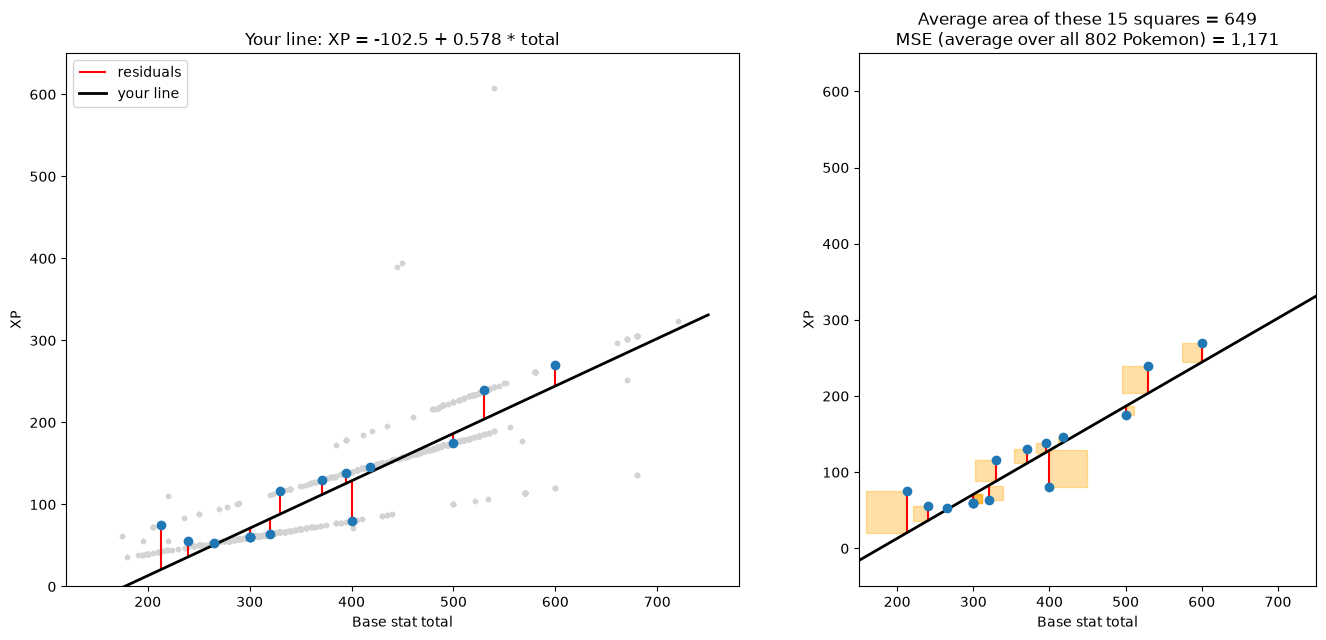

In [7]:
simple = LinearRegression()
simple.fit(poke[["total"]], poke["base_experience"])

b0, b1 = simple.intercept_, simple.coef_[0]
print(f"Best line: XP = {b0:.1f} + {b1:.3f} * total")
print(f"MSE of the best line: {mse_cost(b0, b1):,.0f}")

new = pd.DataFrame({"total": [300, 500]})
print("Predicted XP for totals of 300 and 500:", simple.predict(new).round(1))

draw_line(b0, b1)      # the best line, on the same plot as Interactive 1

Type these values (b0 = -102.5, b1 = 0.578) into the sliders of Interactive 1 to get the same line.

**Reading the line:** the slope is about 0.58, so a Pokemon that is 100 points stronger gives about 58 more XP.
The intercept (-102.5) has no real meaning here, because no Pokemon has a total of 0. It just positions the line.

**Did you notice?** A few dots sit far above the others. Let's see who they are.

In [8]:
poke.sort_values("base_experience", ascending=False)[["pokemon", "total", "hp", "base_experience"]].head(4)

,pokemon,total,hp,base_experience
241,blissey,540,255,608
112,chansey,450,250,395
530,audino,445,103,390
492,arceus,720,120,324


**Blissey** gives 608 XP, the most of any Pokemon, even though its total is only average. **Chansey** and **Audino** are similar.
These are "healer" Pokemon that the game designers chose to make worth a lot of XP. The base stat total cannot know that, so the line misses them badly.

### Exercise 1

1. Compute the MSE of the line $b_0 = -120$, $b_1 = 0.6$ and of the line $b_0 = -50$, $b_1 = 0.45$. Which one is better?
2. Fit a line that predicts `weight` from `height`. What is the slope, and what does it mean?

In [ ]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# 1.
print("Line A:", mse_cost(-120, 0.6))
print("Line B:", mse_cost(-50, 0.45))     # fill in: b0, b1 of line B (numbers)

# 2.
hw = LinearRegression()
hw.fit(poke[["height"]], poke["weight"])      # fill in: feature column, target column (names, keep the quotes)
print("Slope:", hw.coef_[0])

Line A: 1246.2658354114712
Line B: 1375.1135442643392
Slope: 63.664069304977076


In [ ]:
# Line A is better because it has a lower MSE which means that the data fits on 
# that line.

# The slope just means that for every 1 unit of height a pokemon gains it gains around 
# 63 units of weight. 

## Part 2. Multiple Linear Regression

Instead of one feature, we can use several. With the six stats, each stat gets its own coefficient:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_6 x_6$$

Each coefficient tells us how much the prediction changes when that feature goes up by 1 **and the other features stay the same**.

In [13]:
multi = LinearRegression()
multi.fit(poke[STATS], poke["base_experience"])
pd.Series(multi.coef_, index=STATS).round(2)

hp                 0.91
attack             0.38
defense            0.45
special_attack     0.47
special_defense    0.73
speed              0.59
dtype: float64

One point of HP seems to be worth about 0.91 XP, but one point of Attack only 0.38. Is HP really that special?

Not really: the healer Pokemon from Part 1 have huge HP **and** huge XP, and these few Pokemon pull the HP coefficient up.
If you remove them, all six stats are worth about the same. **Lesson:** a few unusual rows can change a coefficient a lot.

### Exercise 2

Fit a model that predicts `base_experience` from `total`, `height` and `weight`. Then predict the XP of a Pokemon with a total of 500, a height of 1.5 m and a weight of 50 kg.

In [11]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# features = ["total", "height", "weight"]
# model2 = LinearRegression()
# model2.fit(poke[features], poke["___"])     # fill in: target column name (keep the quotes)
# print(pd.Series(model2.coef_, index=features))

# new_pokemon = pd.DataFrame({"total": [500], "height": [1.5], "weight": [50]})
# print("Predicted XP:", model2.predict(___))      # fill in: the table to predict for (a variable name, no quotes)

## Part 3. Gradient Descent

`LinearRegression` uses a formula to jump straight to the best line. Most other models (logistic regression, neural networks) have **no** such formula. They find the best values step by step, with **gradient descent**.

### From the cost to the gradient

In Interactive 1, every time you moved a slider the MSE changed. Let's draw that as a curve. We keep the intercept fixed at its best value ($b_0 = -102.5$) and compute the MSE for many values of the slope $b_1$.

The **gradient** is the **slope of this cost curve** at the point where you are (the dashed tangent line):

- gradient **positive**: the cost goes up to the right, so move $b_1$ to the **left** (make it smaller),
- gradient **negative**: the cost goes up to the left, so move $b_1$ to the **right** (make it bigger),
- gradient **0**: you are at the bottom.

Move the slider and check where the arrow points. Can you find the bottom? (The arrow shows only the **direction** of the step. How **big** the step is comes from the learning rate, below.)

In [12]:
B0_FIXED = simple.intercept_          # the best intercept from Part 1 (about -102.5)
b1_values = np.linspace(0.3, 0.85, 200)
cost_curve = [mse_cost(B0_FIXED, b) for b in b1_values]

def gradient_b1(b1):
    # slope of the cost curve at b1 (the gradient for b1 from the formula below)
    residual = poke["base_experience"] - (B0_FIXED + b1 * poke["total"])
    return -2 * np.mean(poke["total"] * residual)

def cost_slope_demo(b1):
    cost_here, grad = mse_cost(B0_FIXED, b1), gradient_b1(b1)
    plt.figure(figsize=(9, 4.5))
    plt.plot(b1_values, cost_curve, color="tab:blue", lw=2.5, label="MSE for each slope b1")
    tangent = np.array([b1 - 0.08, b1 + 0.08])
    plt.plot(tangent, cost_here + grad * (tangent - b1), color="black", ls="--", lw=1.5, label="tangent: its slope is the gradient")
    plt.scatter(b1, cost_here, s=120, color="orange", edgecolor="black", zorder=4, label="you are here")
    if abs(grad) > 500:
        step = -0.06 * np.sign(grad)                      # the arrow only shows the direction
        plt.annotate("", xy=(b1 + step, cost_here), xytext=(b1, cost_here),
                     arrowprops=dict(arrowstyle="->", color="green", lw=3))
    plt.ylim(0, max(cost_curve) * 1.05)
    plt.xlabel("slope b1")
    plt.ylabel("MSE (cost)")
    plt.title(f"b1 = {b1:.3f}     MSE = {cost_here:,.0f}     gradient = {grad:,.0f}")
    plt.legend(loc="upper center")
    plt.show()
    if abs(grad) <= 500:
        print("The gradient is (almost) 0: you are at the bottom of the curve.")
    else:
        print("Gradient is", "positive -> make b1 smaller (green arrow points left)" if grad > 0
              else "negative -> make b1 bigger (green arrow points right)")

interact(cost_slope_demo, b1=FloatSlider(value=0.4, min=0.3, max=0.85, step=0.001, readout_format=".3f",
                                         description="slope b1", continuous_update=False));

interactive(children=(FloatSlider(value=0.4, continuous_update=False, description='slope b1', max=0.85, min=0.…

Gradient descent does exactly this, over and over: compute the slope at the current point, take a small step downhill, repeat. With two parameters ($b_0$ and $b_1$), the curve becomes a bowl-shaped surface (you will see it in 3D below), but the idea is the same.

### Gradient descent

Imagine you are on a hill in thick fog and want to reach the bottom of the valley. You cannot see far, but you can feel which way the ground slopes. So you take a step downhill, feel again, and repeat.

1. Start anywhere, for example $b_0 = 0$ and $b_1 = 0$.
2. Compute the **gradient**: the direction in which the cost goes **up** the fastest.
3. Take a step in the **opposite** direction: $\;b \leftarrow b - \text{learning rate} \times \text{gradient}$
4. Repeat until the cost stops going down. This is called **convergence**.

The **learning rate** is the size of each step. For the MSE, the gradients are:

$$\text{gradient for } b_0 = -2 \times \text{average}(\text{residual}) \qquad \text{gradient for } b_1 = -2 \times \text{average}(x \times \text{residual})$$

First we **standardize** the total: subtract the mean, then divide by the standard deviation. Now x is centered at 0 with a spread of about 1.

**Why?** Gradient descent uses **one** learning rate for both $b_0$ and $b_1$. With raw totals (around 400), the gradient for $b_1$ is hundreds of times bigger than the gradient for $b_0$, so no single step size suits both. We tried it on the raw totals: a learning rate of 0.1 makes the cost explode, and a learning rate small enough to be safe (0.000001) has still not reached the bottom after 10,000 steps. On the standardized total, 50 steps are enough.

In [13]:
x = ((poke["total"] - poke["total"].mean()) / poke["total"].std()).to_numpy()
y = poke["base_experience"].to_numpy()

def gradient_descent(learning_rate, n_steps):
    b0, b1 = 0.0, 0.0                          # 1. start anywhere
    costs = []
    for step in range(n_steps):
        residual = y - (b0 + b1 * x)
        costs.append(np.mean(residual ** 2))
        grad_b0 = -2 * np.mean(residual)       # 2. compute the gradient
        grad_b1 = -2 * np.mean(x * residual)
        b0 = b0 - learning_rate * grad_b0      # 3. take a step downhill
        b1 = b1 - learning_rate * grad_b1
    return b0, b1, costs

b0_gd, b1_gd, costs = gradient_descent(learning_rate=0.1, n_steps=50)
print(f"After 50 steps: b0 = {b0_gd:.2f}, b1 = {b1_gd:.2f}, cost = {costs[-1]:,.1f}")

After 50 steps: b0 = 141.03, b1 = 64.11, cost = 1,170.9


The final cost (about 1,171) is the same lowest MSE as in Part 1, so gradient descent found **the same best line**.

The numbers $b_0 = 141$ and $b_1 = 64$ look different from Part 1 only because x is now measured on the standardized scale:

- $b_0 = 141$: the predicted XP of an **average** Pokemon (x = 0).
- $b_1 = 64$: the extra XP for a Pokemon that is one standard deviation (about 111 points) stronger.

We will keep working on the standardized scale for the rest of this part.

### Interactive 2: Choose the learning rate

Change the learning rate and the number of steps. Watch the cost on the left and the line on the right.

- Try **0.01**, **0.1**, **0.5**, **0.9** and **1.05**. Which one is too slow? Which one bounces back and forth? Which one explodes?

In [14]:
def gd_demo(learning_rate, n_steps):
    b0, b1, costs = gradient_descent(learning_rate, n_steps)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(range(1, n_steps + 1), costs, "o-")
    ax1.axhline(1171, color="green", ls="--", label="lowest possible cost")
    ax1.set_yscale("log")
    ax1.set_xlabel("Step")
    ax1.set_ylabel("Cost (MSE, log scale)")
    ax1.set_title("Cost at each step")
    ax1.legend()

    ax2.scatter(x, y, color="lightgray", s=10)
    for step in range(1, n_steps):                     # faint lines: the line after each earlier step
        s0, s1, _ = gradient_descent(learning_rate, step)
        ax2.plot([-3, 3], [s0 - 3 * s1, s0 + 3 * s1], color="tab:orange", alpha=0.3)
    ax2.plot([-3, 3], [b0 - 3 * b1, b0 + 3 * b1], color="black", lw=2)
    ax2.set_ylim(0, 650)
    ax2.set_xlabel("Base stat total (standardized)")
    ax2.set_ylabel("XP")
    ax2.set_title("The line at each step (black = last step)")
    plt.tight_layout()
    plt.show()

    final_cost = np.mean((y - (b0 + b1 * x)) ** 2)
    if final_cost > costs[0]:
        print("The cost went UP: the learning rate is too large and gradient descent diverges.")
    elif final_cost < 1180:
        print(f"Converged: you reached the bottom of the valley (cost = {final_cost:,.0f}).")
    else:
        print(f"Not at the bottom yet (cost = {final_cost:,.0f}). Try more steps or a different learning rate.")

interact(gd_demo,
         learning_rate=FloatSlider(value=0.01, min=0.01, max=1.1, step=0.01, description="learning rate", continuous_update=False),
         n_steps=IntSlider(value=20, min=1, max=50, description="steps", continuous_update=False));

interactive(children=(FloatSlider(value=0.01, continuous_update=False, description='learning rate', max=1.1, m…

### The cost in 3D

Every pair of values $(b_0, b_1)$ is one possible line, and each line has a cost. Plotting the cost for every pair gives a **bowl**. Gradient descent walks down this bowl to the bottom.

Drag to rotate the bowl, scroll to zoom. Move the slider under the plot to change the learning rate and watch the orange path.

In [15]:
import plotly.graph_objects as go

B0, B1 = np.meshgrid(np.linspace(-20, 300, 60), np.linspace(-20, 150, 60))
COST = np.array([[np.mean((y - (b0 + b1 * x)) ** 2) for b0, b1 in zip(r0, r1)] for r0, r1 in zip(B0, B1)])

RATES = [0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
fig = go.Figure([go.Surface(x=B0, y=B1, z=COST, colorscale="Blues", opacity=0.7, showscale=False)])
for k, lr in enumerate(RATES):
    path = [gradient_descent(lr, n)[:2] for n in range(21)]          # where we are after 0, 1, ..., 20 steps
    p0, p1 = [p[0] for p in path], [p[1] for p in path]
    pc = [np.mean((y - (a + b * x)) ** 2) for a, b in path]
    fig.add_trace(go.Scatter3d(x=p0, y=p1, z=pc, mode="lines+markers", visible=(lr == 0.1),
                               line=dict(color="orange", width=6), marker=dict(size=4, color="orange"),
                               name=f"learning rate {lr}"))

# a slider inside the plot: each position shows the path for one learning rate
steps = [dict(label=str(lr), method="update",
              args=[{"visible": [True] + [j == k for j in range(len(RATES))]}])
         for k, lr in enumerate(RATES)]
fig.update_layout(height=600, title="The cost bowl with 20 steps of gradient descent",
                  sliders=[dict(active=RATES.index(0.1), currentvalue=dict(prefix="learning rate: "), steps=steps)],
                  scene=dict(xaxis_title="b0 (intercept)", yaxis_title="b1 (slope)", zaxis_title="cost (MSE)",
                             zaxis=dict(range=[0, COST.max()])))
fig.show()

| Learning rate | What happens |
|---|---|
| Too small (0.01) | tiny steps: the cost goes down, but very slowly |
| Good (0.1 to 0.5) | reaches the bottom quickly |
| Large (0.9) | each step jumps over the bottom to the other side: watch the orange lines flip above and below the data |
| Exactly 1.0 | the intercept jumps back and forth forever and never settles |
| Too large (above 1.0) | each jump lands higher than before: the cost explodes (the model **diverges**) |

On big datasets, each step often uses only a small random group of rows instead of all of them. This is called **stochastic** or **mini-batch** gradient descent.

### Exercise 3

Run gradient descent for 50 steps with three learning rates: 0.01, 0.1 and 1.05. Print the final cost for each. Which one converged?

In [16]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# for lr in [0.01, 0.1, 1.05]:
#     b0, b1, costs = gradient_descent(learning_rate=___, n_steps=50)     # fill in: the loop variable
#     print(f"learning rate {lr}: final cost = {costs[-1]:,.1f}")

## Part 4. Evaluating a Model

A model is only useful if it predicts well on **new** data. So we split the Pokemon into two groups:

- a **training set** (75%) that the model learns from, and
- a **test set** (25%) that we hide from the model and use only to check its predictions.

In [17]:
train, test = train_test_split(poke, test_size=0.25, random_state=42)
print("Training Pokemon:", len(train), "   Test Pokemon:", len(test))

model_a = LinearRegression().fit(train[["total"]], train["base_experience"])
pred_a = model_a.predict(test[["total"]])

Training Pokemon: 601    Test Pokemon: 201


### Three common scores

| Score | In words | Good value |
|---|---|---|
| **MAE** (mean absolute error) | the average size of a miss, in XP | small |
| **RMSE** (root mean squared error) | the square root of the MSE, back in XP. Big misses count more | small |
| **R-squared** | the share of the differences in XP that the model explains | close to 1 |

R-squared is 1 for perfect predictions and 0 for a model that is no better than always guessing the average. On test data it can even be negative: worse than guessing the average.

In [18]:
def scores(actual, predicted):
    return pd.Series({"MAE": mean_absolute_error(actual, predicted),
                      "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
                      "R-squared": r2_score(actual, predicted)}).round(3)

scores(test["base_experience"], pred_a)

MAE          19.039
RMSE         25.828
R-squared     0.871
dtype: float64

The model misses by about **19 XP** on average and explains about **87%** of the differences in XP.

A picture helps too: if every prediction were perfect, every dot would sit on the dashed line.

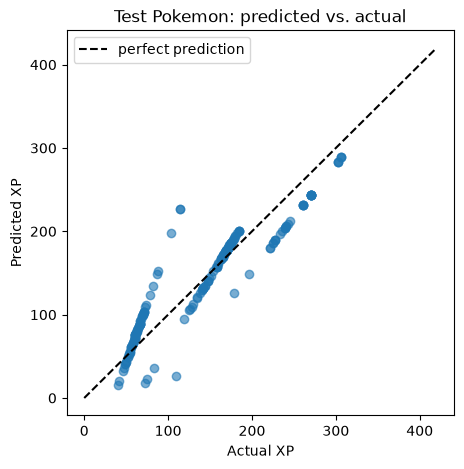

In [19]:
plt.figure(figsize=(5, 5))
plt.scatter(test["base_experience"], pred_a, alpha=0.6)
plt.plot([0, 420], [0, 420], color="black", ls="--", label="perfect prediction")
plt.xlabel("Actual XP")
plt.ylabel("Predicted XP")
plt.title("Test Pokemon: predicted vs. actual")
plt.legend()
plt.show()

### The three metrics as cost bowls

In Part 3 we drew the MSE as a **bowl**: every point on the floor is one line $(b_0, b_1)$, and the height above it is the cost of that line. The **gradient** is simply **how steep the bowl is under your feet, and in which direction it goes up**. Gradient descent steps the opposite way, downhill.

Nothing forces us to use the MSE as the cost. We can draw the same bowl with MAE or RMSE as the height. The data and the lines are the same; only the way we score the misses changes:

- **MSE**: square each miss, then average.
- **RMSE**: the square root of the MSE.
- **MAE**: take the size of each miss (drop the minus sign), then average.

The code below scores 6,561 lines (an 81 by 81 grid of $b_0$ and $b_1$ values) with each metric. As in Part 3, x is the standardized total. The red dot marks the lowest point of each bowl. Drag each bowl to rotate it.

In [20]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# a grid of lines around the best line (b0 about 141, b1 about 64 on the standardized x from Part 3)
G0, G1 = np.meshgrid(np.linspace(40, 240, 81), np.linspace(-35, 165, 81))

# the residuals of every line on the grid for every Pokemon (shape: 81 x 81 x 802)
miss_grid = y - (G0[..., None] + G1[..., None] * x)

bowls = {"MSE":  np.mean(miss_grid ** 2, axis=2),
         "RMSE": np.sqrt(np.mean(miss_grid ** 2, axis=2)),
         "MAE":  np.mean(np.abs(miss_grid), axis=2)}

fig = make_subplots(rows=1, cols=3, specs=[[{"type": "surface"}] * 3],
                    subplot_titles=["MSE bowl", "RMSE bowl", "MAE bowl"])
for k, (name, cost) in enumerate(bowls.items()):
    low = np.unravel_index(cost.argmin(), cost.shape)          # grid position of the lowest point
    fig.add_trace(go.Surface(x=G0, y=G1, z=cost, colorscale="Blues", opacity=0.85, showscale=False),
                  row=1, col=k + 1)
    fig.add_trace(go.Scatter3d(x=[G0[low]], y=[G1[low]], z=[cost[low]], mode="markers",
                               marker=dict(size=6, color="red"), showlegend=False),
                  row=1, col=k + 1)
    print(f"{name:4s} lowest point: b0 = {G0[low]:.1f}, b1 = {G1[low]:.1f}, cost = {cost[low]:,.1f}")

scene = dict(xaxis_title="b0", yaxis_title="b1", zaxis_title="cost",
             camera=dict(eye=dict(x=1.6, y=1.6, z=0.9)))
fig.update_layout(height=480, margin=dict(l=0, r=0, t=40, b=0), scene=scene, scene2=scene, scene3=scene)
fig.show()

MSE  lowest point: b0 = 140.0, b1 = 65.0, cost = 1,172.7
RMSE lowest point: b0 = 140.0, b1 = 65.0, cost = 34.2
MAE  lowest point: b0 = 137.5, b1 = 67.5, cost = 21.0


In 3D the shapes are easier to compare if we cut each bowl straight through its middle. Below, we keep the slope fixed at $b_1 = 65$ (the best slope) and only change the intercept $b_0$. Each curve is the outline of one bowl.

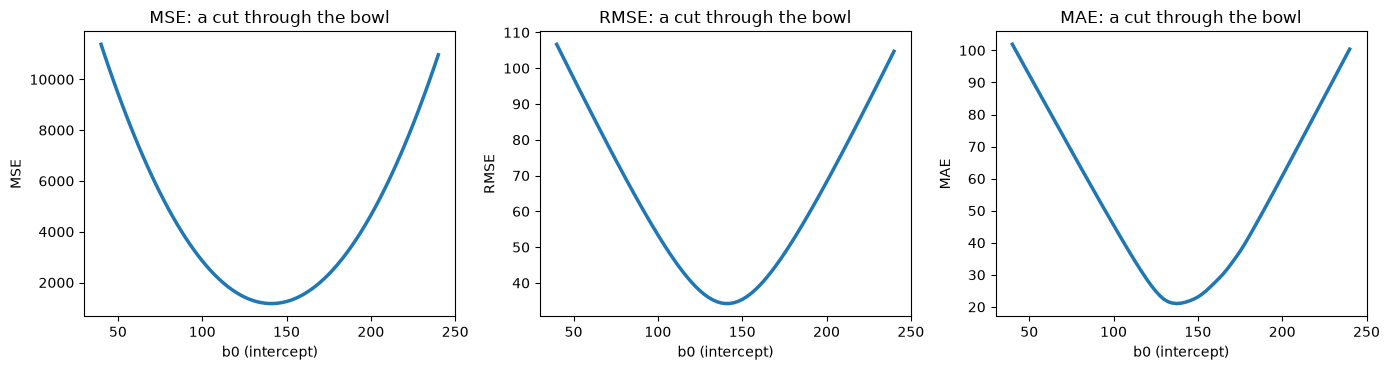

In [21]:
middle = len(G1) // 2              # the middle row of the grid, where b1 = 65
b0_line = G0[middle]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, cost) in zip(axes, bowls.items()):
    ax.plot(b0_line, cost[middle], lw=2.5)
    ax.set(title=f"{name}: a cut through the bowl", xlabel="b0 (intercept)", ylabel=name)
plt.tight_layout()
plt.show()

### What shapes did we get?

| | MSE | RMSE | MAE |
|---|---|---|---|
| Shape | a round bowl (U shape) | a cone with a rounded tip (V shape) | a cone with a sharper tip (V shape) |
| Walls | get steeper and steeper as you move away | straight | straight |
| Lowest point | the best line from Part 1 | **the same point** as MSE | a slightly **different** point |
| Units of the height | XP squared | XP | XP |

**Why do MSE and RMSE have the same lowest point?** The square root never changes the order: a line with a smaller MSE always has a smaller RMSE. So both bowls pick the same best line. The square root only squashes the heights, which turns the U into a V.

**Why is the MAE bottom in a slightly different place?** MSE looks for the line that is right **on average** (like a mean). MAE looks for the line with about half of the Pokemon above it and half below it (like a **median**).

### What this means for the gradient

Remember: the gradient is the steepness of the wall under your feet.

- **MSE**: far from the bottom the walls are very steep, so the gradient is big and the steps are big. Near the bottom the floor flattens out, so the gradient shrinks smoothly to 0 and the steps get smaller **by themselves**. This is why gradient descent with one fixed learning rate settles nicely in Part 3.
- **RMSE**: the walls are straight, so the gradient has about the same size everywhere except near the tip. Being far away no longer means taking bigger steps.
- **MAE**: also straight walls, but if you zoom in very closely, the surface is made of many small flat pieces joined at creases (one crease for each Pokemon, where the line passes exactly through its dot). The gradient stays the same on each flat piece and jumps at each crease, so it does not shrink smoothly near the bottom. With a fixed learning rate, gradient descent tends to hop back and forth around the bottom.

This is one reason why models are usually **trained** with MSE (smooth, easy to walk down) and then **judged** with whichever metric is easiest to explain, such as MAE or RMSE in XP.

**Data Story: what if the healers were not in the data?**

Remember the four healer Pokemon from Part 1 (Blissey, Chansey, Audino, Happiny): they give far more XP than the line predicts. They are only 4 of 802 Pokemon (0.5%). Below, each bowl is drawn twice, zoomed in around the bottom: **blue** with all Pokemon, **orange** without the four healers. The flat plots underneath cut each pair of bowls through the middle.

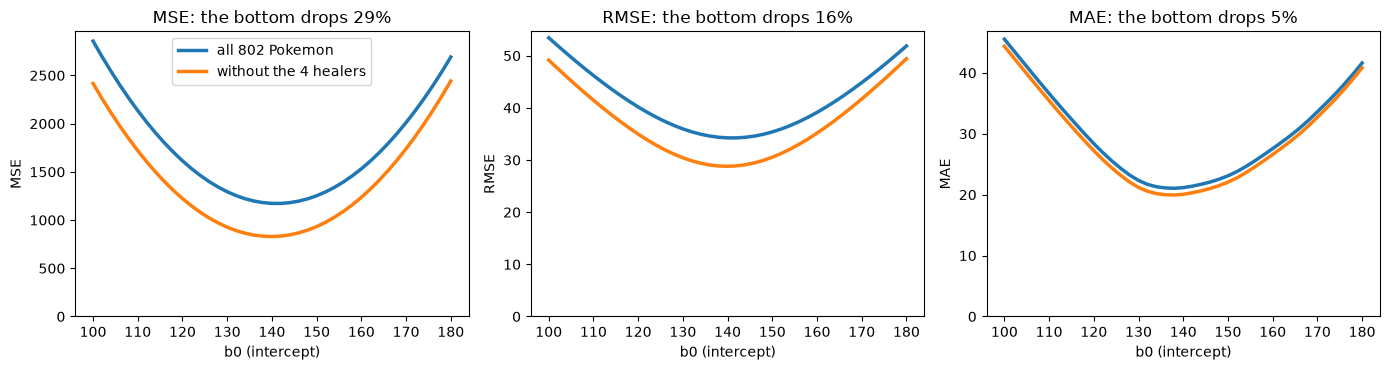

,bottom with healers,bottom without healers,drop
metric,,,
MSE,1172.6,827.8,29%
RMSE,34.2,28.8,16%
MAE,21.0,19.8,5%


In [22]:
healer = poke["pokemon"].isin(["blissey", "chansey", "audino", "happiny"]).to_numpy()

# a zoomed-in grid around the bottom of the bowls
Z0, Z1 = np.meshgrid(np.linspace(100, 180, 41), np.linspace(25, 105, 41))

def three_bowls(xv, yv):
    miss = yv - (Z0[..., None] + Z1[..., None] * xv)
    return {"MSE": np.mean(miss ** 2, axis=2),
            "RMSE": np.sqrt(np.mean(miss ** 2, axis=2)),
            "MAE": np.mean(np.abs(miss), axis=2)}

with_healers = three_bowls(x, y)
without_healers = three_bowls(x[~healer], y[~healer])

fig = make_subplots(rows=1, cols=3, specs=[[{"type": "surface"}] * 3],
                    subplot_titles=["MSE", "RMSE", "MAE"])
rows = []
for k, name in enumerate(["MSE", "RMSE", "MAE"]):
    for label, cost, color in [("all 802 Pokemon", with_healers[name], "Blues"),
                               ("without the 4 healers", without_healers[name], "Oranges")]:
        fig.add_trace(go.Surface(x=Z0, y=Z1, z=cost, colorscale=color, opacity=0.75, showscale=False,
                                 name=label, showlegend=False), row=1, col=k + 1)
    low_with, low_without = with_healers[name].min(), without_healers[name].min()
    rows.append({"metric": name, "bottom with healers": low_with, "bottom without healers": low_without,
                 "drop": f"{1 - low_without / low_with:.0%}"})

scene = dict(xaxis_title="b0", yaxis_title="b1", zaxis_title="cost", camera=dict(eye=dict(x=1.8, y=-1.4, z=0.5)))
fig.update_layout(height=500, margin=dict(l=0, r=0, t=80, b=0), scene=scene, scene2=scene, scene3=scene,
                  title=dict(text="Blue: all 802 Pokemon.   Orange: without Blissey, Chansey, Audino and Happiny.", y=0.97))
fig.show()

# the same bowls cut through the middle (b1 = 65), with and without the healers
middle = len(Z1) // 2
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, row in zip(axes, rows):
    name = row["metric"]
    ax.plot(Z0[middle], with_healers[name][middle], color="tab:blue", lw=2.5, label="all 802 Pokemon")
    ax.plot(Z0[middle], without_healers[name][middle], color="tab:orange", lw=2.5, label="without the 4 healers")
    ax.set_ylim(0, None)
    ax.set(title=f"{name}: the bottom drops {row['drop']}", xlabel="b0 (intercept)", ylabel=name)
axes[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("metric").round(1)

**What to notice:**

- The bottom of each bowl stays in almost the **same place**: $b_0$ and $b_1$ change by about 1. The healers barely change **which line is best**.
- But the **height** of the bottom (the cost of the best line) drops by very different amounts:

| | MSE | RMSE | MAE |
|---|---|---|---|
| Drop without the 4 healers | 29% | 16% | 5% |

Squaring turns Blissey's miss of about 400 XP into about 160,000, so four Pokemon make up almost a third of the MSE. The square root in RMSE softens this and brings the number back to XP. MAE counts every XP of miss the same, so four Pokemon barely move it.

**Which one gives a better estimate of the cost?** It depends on the question you ask:

| Metric | Best for | Watch out |
|---|---|---|
| MSE | **training** the model: a smooth bowl that gradient descent can walk down | units are XP squared, and a few rows can dominate it |
| RMSE | reporting in XP when **big misses are costly** | still pulled up by a few huge misses |
| MAE | reporting the **typical miss** in XP (about 20 XP, with or without the healers) | ignores whether a miss is one big one or many small ones |

### Exercise 4

Fit a model that uses **only** `height` and `weight` (on the training set), and score it on the test set. Is it better or worse than the model that uses `total`?

In [23]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# model_hw = LinearRegression()
# model_hw.fit(train[["height", "weight"]], train["base_experience"])
# pred_hw = model_hw.predict(test[["___", "___"]])     # fill in: the same two column names used in fit

# scores(test["base_experience"], ___)     # fill in: your predictions (a variable name, no quotes)

## Part 5. Logistic Regression

Now a **yes or no** question: **is this Pokemon tall (at least 1 meter)?** Predicting a category is called **classification**. The label `tall` is 1 for yes and 0 for no, and about half of all Pokemon are tall.

Stronger Pokemon tend to be bigger, so we use the base stat total again as the feature.

Why not just use a straight line on the 0/1 label? A line can predict values below 0 or above 1, which make no sense as probabilities. We need a curve that always stays between 0 and 1.

### The sigmoid function

Logistic regression computes the same score as before, $z = b_0 + b_1 x$, and passes it through the **sigmoid** function:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The sigmoid squeezes any number into the range 0 to 1, so we can read the result as a **probability**.

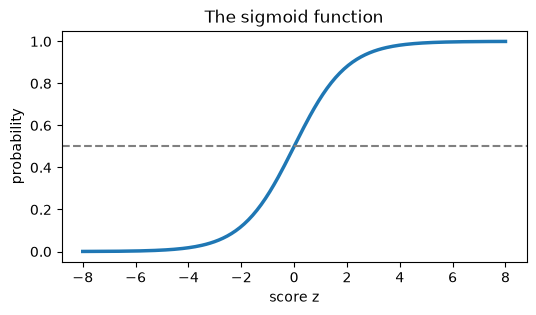

In [24]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, sigmoid(z), lw=2.5)
plt.axhline(0.5, color="gray", ls="--")
plt.xlabel("score z")
plt.ylabel("probability")
plt.title("The sigmoid function")
plt.show()

Now we fit a logistic regression that predicts `tall` from `total`. `predict_proba` gives two columns, P(not tall) and P(tall); we keep the second one with `[:, 1]`.

In [25]:
logit = LogisticRegression()
logit.fit(train[["total"]], train["tall"])

examples = pd.DataFrame({"total": [200, 300, 400, 500, 600]})
examples["P(tall)"] = logit.predict_proba(examples)[:, 1].round(3)
examples

,total,P(tall)
0,200,0.023
1,300,0.117
2,400,0.423
3,500,0.802
4,600,0.957


A Pokemon with a total of 200 has only a 2% chance of being tall, and one with 600 has a 96% chance. In between, the probability rises gradually: at 400 the model is unsure (42%).

### Interactive 3: Move the threshold

To turn a probability into a yes or no, we pick a **threshold**: say "tall" if the probability is at least the threshold. The total where the curve crosses the threshold is the **decision boundary**.

Move the threshold and watch how the mistakes change on the 201 test Pokemon.

- A **false alarm** is a short Pokemon that the model calls tall.
- A **miss** is a tall Pokemon that the model calls short.

The dots are spread up and down a little so that Pokemon with the same total do not hide each other.

Can you find a threshold with no misses? How few false alarms can you get? Can you make both zero at the same time?

In [26]:
curve = pd.DataFrame({"total": np.arange(150, 760)})
curve_p = logit.predict_proba(curve)[:, 1]
p_test = logit.predict_proba(test[["total"]])[:, 1]
is_tall = test["tall"].to_numpy() == 1
jitter = np.random.default_rng(0).uniform(-0.07, 0.07, len(test))     # small random spread, only for drawing

def threshold_demo(threshold):
    says_yes = p_test >= threshold
    boundary = curve["total"][curve_p >= threshold].min()

    plt.figure(figsize=(11, 4))
    plt.plot(curve["total"], curve_p, color="purple", lw=2, label="P(tall)")
    plt.scatter(test["total"], test["tall"] + jitter, c=np.where(says_yes == is_tall, "tab:green", "tab:red"),
                alpha=0.6, s=20)
    plt.axhline(threshold, color="black", ls="--", label=f"threshold = {threshold:.2f}")
    plt.axvline(boundary, color="gray", ls=":", label=f"decision boundary: total = {boundary}")
    plt.xlabel("Base stat total")
    plt.ylabel("tall (1 = yes, 0 = no)")
    plt.title("Green = correct, red = mistake")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

    print("Tall Pokemon found:", np.sum(says_yes & is_tall), "of", np.sum(is_tall))
    print("False alarms:      ", np.sum(says_yes & ~is_tall))
    print("Misses:            ", np.sum(~says_yes & is_tall))
    print(f"Accuracy: {np.mean(says_yes == is_tall):.1%}")

interact(threshold_demo,
         threshold=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="threshold", continuous_update=False));

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='threshold', max=0.95, min=0…

With the usual threshold of 0.5, the model is right for **80%** of the test Pokemon. Is that good? Compare it with a simple **baseline**: 106 of the 201 test Pokemon are tall, so a "model" that **always** says "tall" is right **53%** of the time. The base stat total clearly helps, but it is far from perfect.

There is no threshold without mistakes: some strong Pokemon are small, and some weak Pokemon are big. Lowering the threshold catches more tall Pokemon but adds false alarms; raising it does the opposite.

**Which threshold is best?** It depends on which mistake costs more. A medical test for a serious disease uses a **low** threshold, because missing a sick patient is much worse than a false alarm.

**Did you notice?** Some of the biggest false alarms are tiny legendaries: **Celebi** (0.6 m), **Victini** (0.4 m) and **Azelf** (0.3 m) all have totals near 600, so the model is sure they are tall. On the other side, **Slowpoke** is 1.2 m tall with a total of only 315. The model only sees the total, so it cannot get these right.

### Log loss: the cost function for classification

To train logistic regression we use **log loss** instead of MSE. For one Pokemon:

- if it **is** tall, the penalty is $-\log(p)$,
- if it is **not** tall, the penalty is $-\log(1 - p)$,

where $p$ is the predicted probability of being tall. Log loss is the average penalty. It punishes answers that are **confident and wrong** very hard:

In [27]:
for p in [0.9, 0.5, 0.1, 0.01]:
    print(f"A tall Pokemon, predicted p = {p}: penalty = {-np.log(p):.2f}")

A tall Pokemon, predicted p = 0.9: penalty = 0.11
A tall Pokemon, predicted p = 0.5: penalty = 0.69
A tall Pokemon, predicted p = 0.1: penalty = 2.30
A tall Pokemon, predicted p = 0.01: penalty = 4.61


### Interactive: The log loss penalty

Pick the **true answer** and the model's **predicted probability** that the Pokemon is tall. The dot shows the penalty.

- Make the model right and confident. How small is the penalty?
- Make it wrong and confident (for example, a tall Pokemon with p = 0.01). What happens?

In [28]:
from ipywidgets import ToggleButtons

def log_loss_demo(true_answer, p):
    p_grid = np.linspace(0.001, 0.999, 300)
    if true_answer == "tall (y = 1)":
        curve, penalty, color = -np.log(p_grid), -np.log(p), "tab:green"
    else:
        curve, penalty, color = -np.log(1 - p_grid), -np.log(1 - p), "tab:orange"

    plt.figure(figsize=(8, 4))
    plt.plot(p_grid, curve, color=color, lw=2.5, label=f"penalty when the Pokemon is {true_answer}")
    plt.scatter(p, penalty, s=150, color="black", zorder=3)
    plt.vlines(p, 0, penalty, color="black", ls=":")
    plt.ylim(0, 7)
    plt.xlabel("Predicted probability of being tall (p)")
    plt.ylabel("Penalty")
    plt.title(f"Penalty = {penalty:.2f}")
    plt.legend(loc="upper center")
    plt.tight_layout()
    plt.show()

interact(log_loss_demo,
         true_answer=ToggleButtons(options=["tall (y = 1)", "not tall (y = 0)"], description="true answer"),
         p=FloatSlider(value=0.9, min=0.01, max=0.99, step=0.01, description="predicted p", continuous_update=False));

interactive(children=(ToggleButtons(description='true answer', options=('tall (y = 1)', 'not tall (y = 0)'), v…

Being 90% sure and right costs only 0.11. Being 99% sure and wrong (p = 0.01) costs 4.61, about 40 times more. Logistic regression is trained by minimizing log loss with **gradient descent**, the same idea as in Part 3 (scikit-learn uses a faster variant of it).

### Exercise 5

1. Use `predict_proba` to find the probability of being tall for totals of 300, 420 and 550.
2. Compute the probability for a total of 420 **by hand** with the sigmoid: $z = b_0 + b_1 \times 420$. Do you get the same answer?

In [29]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# 1.
# totals = pd.DataFrame({"total": [300, 420, 550]})
# print(logit.predict_proba(___)[:, 1])     # fill in: the table of totals (a variable name, no quotes)

# 2.
# b0, b1 = logit.intercept_[0], logit.coef_[0][0]
# z = b0 + b1 * ___     # fill in: the total (a number)
# print("By hand:", sigmoid(z))

## Part 6. Overfitting

We can make a model more **flexible** by adding powers of the feature: $x^2, x^3, \dots$ This is **polynomial regression**, and the highest power is called the **degree**. A higher degree gives a curve that can bend more.

More flexible is not always better:

- **Underfitting:** the model is too simple and misses the pattern (for example, a flat line).
- **Overfitting:** the model is so flexible that it memorizes the training data, including its noise. It looks great on the training data but predicts badly on new data.

To see this clearly, we train on only **30** Pokemon and test on the other 772.

In [30]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

small_train, big_test = train_test_split(poke, train_size=30, random_state=11)

def poly_model(degree):
    # adds x, x^2, ..., x^degree as new columns, then fits a linear regression
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())

def rmse(model, data):
    return np.sqrt(mean_squared_error(data["base_experience"], model.predict(data[["total"]])))

### Interactive 4: Bend the curve

Move the degree from 0 to 8. Watch the training error and the test error.

- Which degree **underfits**?
- At which degree does the curve start to go wild near the edges?

In [31]:
grid = pd.DataFrame({"total": np.linspace(175, 720, 300)})

def overfit_demo(degree):
    model = poly_model(degree).fit(small_train[["total"]], small_train["base_experience"])
    plt.figure(figsize=(9, 4.5))
    plt.scatter(big_test["total"], big_test["base_experience"], color="lightgray", s=10, label="test Pokemon (772)")
    plt.scatter(small_train["total"], small_train["base_experience"], color="tab:blue", s=40, label="training Pokemon (30)")
    plt.plot(grid["total"], model.predict(grid), color="tab:red", lw=2.5, label=f"degree {degree} curve")
    plt.ylim(0, 450)
    plt.xlabel("Base stat total")
    plt.ylabel("XP")
    plt.title(f"Training RMSE = {rmse(model, small_train):.0f} XP      Test RMSE = {rmse(model, big_test):.0f} XP")
    plt.legend(loc="upper left")
    plt.show()

interact(overfit_demo, degree=IntSlider(value=0, min=0, max=8, description="degree", continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='degree', max=8), Output()), _do…

The same story in one chart: as the degree grows, the **training** error keeps going down, but the **test** error goes down and then shoots up.

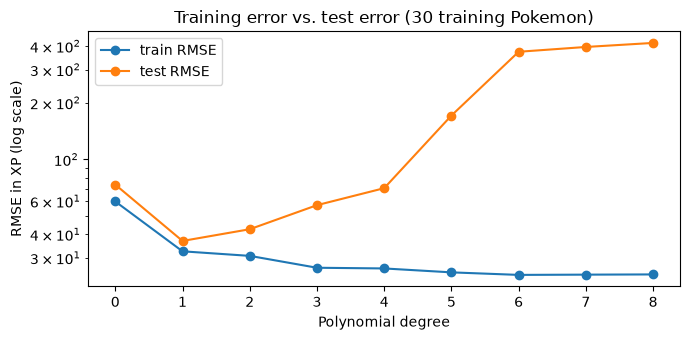

,train RMSE,test RMSE
degree,,
0,59.7,73.4
1,32.5,36.9
2,30.7,42.5
3,26.6,57.1
4,26.3,70.3
5,25.1,170.9
6,24.3,372.9
7,24.4,395.5
8,24.5,415.5


In [32]:
def error_table(train_size):
    tr, te = train_test_split(poke, train_size=train_size, random_state=11)
    rows = []
    for degree in range(9):
        model = poly_model(degree).fit(tr[["total"]], tr["base_experience"])
        rows.append({"degree": degree, "train RMSE": rmse(model, tr), "test RMSE": rmse(model, te)})
    return pd.DataFrame(rows).set_index("degree")

errors = error_table(30)
errors.plot(marker="o", logy=True, figsize=(7, 3.5), title="Training error vs. test error (30 training Pokemon)")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE in XP (log scale)")
plt.tight_layout()
plt.show()
errors.round(1)

The best model is at the bottom of the test error curve: **degree 1**, a straight line.

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| Model | too simple | just right | too flexible |
| Training error | high | low | very low |
| Test error | high | low | high |
| How to fix | use a more flexible model or more features | | use more data, a simpler model, or **regularization** |

**Regularization** adds a penalty for large coefficients to the cost function, which keeps the curve from bending too much. The best-known example is **Ridge** regression (`from sklearn.linear_model import Ridge`).

### Exercise 6

Run `error_table` with **100** training Pokemon instead of 30. Does the test error still explode at degree 8? Why do you think more data helps?

In [33]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# error_table(___).round(1)     # fill in: number of training Pokemon (a number)

## Part 7. Final Challenge: Beat the Baseline

Build the model with the **lowest test RMSE** for predicting `base_experience`. The `challenge` function below trains a linear regression on 601 Pokemon using the features you choose and tests it on the other 201.

The model with only `total` scores an RMSE of about **36.6 XP**. Can you beat it? You may create new columns in `poke`.

*A warning about fairness:* every time you try new features and keep the best test score, you are using the test set to make choices, so the score becomes a little too optimistic. In real projects, choices like this are made on a separate **validation set**, and the test set is used only once at the very end.

In [34]:
def challenge(features):
    tr, te = train_test_split(poke, test_size=0.25, random_state=2026)
    model = LinearRegression().fit(tr[features], tr["base_experience"])
    score = np.sqrt(mean_squared_error(te["base_experience"], model.predict(te[features])))
    print(f"RMSE = {score:.2f} XP   using {features}")

challenge(["total"])     # the score to beat

RMSE = 36.60 XP   using ['total']


<details>
<summary><b>Hint</b> (click to open)</summary>

- Remember the healer Pokemon (Blissey, Chansey, Audino, Happiny) that give much **more** XP than expected. A 0/1 column for them can help:
  `poke["healer"] = poke["pokemon"].isin(["blissey", "chansey", "audino", "happiny"]).astype(int)`
- Legendary Pokemon from **Generation 7** give much **less** XP than other legendaries. Try a column that is 1 only when both are true:
  `poke["legendary_gen7"] = poke["legendary"] * (poke["generation_id"] == 7).astype(int)`

</details>

In [35]:
# Your code here. Starter code: remove the # in front of a line and replace each ___

# Your code here: create new columns, then call challenge([...])

## Summary

| Topic | Key idea |
|---|---|
| Linear regression | predict a number with a line, $\hat{y} = b_0 + b_1 x$ |
| Cost function (MSE) | the average squared miss; the best line has the lowest MSE |
| Multiple regression | each feature gets its own coefficient |
| Gradient descent | take small steps downhill until the cost stops going down |
| Learning rate | the step size: too small is slow, too large explodes |
| Evaluation | judge a model on a test set with MAE, RMSE and R-squared |
| Logistic regression | the sigmoid turns a score into a probability between 0 and 1 |
| Threshold | turns a probability into yes or no; the best one depends on the cost of each mistake |
| Log loss | the cost function for classification; punishes confident mistakes |
| Overfitting | a model that is too flexible memorizes the training data and fails on new data |

Almost every machine learning model follows the same loop: choose a model, choose a **cost function**, minimize it with **gradient descent**, and check the result on **data the model has never seen**.